In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# **`Descriptive Analytics for Numerical Columns`**

**Load the dataset into a data analysis tool or programming environment (e.g., Python with pandas library).**

In [2]:
df = pd.read_csv('sales_data_with_discounts.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               450 non-null    object 
 1   Day                450 non-null    object 
 2   SKU                450 non-null    object 
 3   City               450 non-null    object 
 4   Volume             450 non-null    int64  
 5   BU                 450 non-null    object 
 6   Brand              450 non-null    object 
 7   Model              450 non-null    object 
 8   Avg Price          450 non-null    int64  
 9   Total Sales Value  450 non-null    int64  
 10  Discount Rate (%)  450 non-null    float64
 11  Discount Amount    450 non-null    float64
 12  Net Sales Value    450 non-null    float64
dtypes: float64(3), int64(3), object(7)
memory usage: 45.8+ KB


**Identify numerical columns in the dataset.**

In [4]:
numerical_columns = df.select_dtypes(include = ['int64', 'float64'])
numerical_columns

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
0,15,12100,181500,11.654820,21153.498820,160346.501180
1,10,10100,101000,11.560498,11676.102961,89323.897039
2,7,16100,112700,9.456886,10657.910157,102042.089843
3,6,20100,120600,6.935385,8364.074702,112235.925298
4,3,8100,24300,17.995663,4372.946230,19927.053770
...,...,...,...,...,...,...
445,2,1300,2600,15.475687,402.367873,2197.632127
446,6,2600,15600,17.057027,2660.896242,12939.103758
447,2,1600,3200,18.965550,606.897606,2593.102394
448,3,1900,5700,16.793014,957.201826,4742.798174


**Calculate the mean, median, mode, and standard deviation for these columns.**

In [5]:
#mean
mean = numerical_columns.mean()
mean

,0
Volume,5.066667
Avg Price,10453.433333
Total Sales Value,33812.835556
Discount Rate (%),15.155242
Discount Amount,3346.499424
Net Sales Value,30466.336131


In [6]:
#median
median = numerical_columns.median()
median

,0
Volume,4.000000
Avg Price,1450.000000
Total Sales Value,5700.000000
Discount Rate (%),16.577766
Discount Amount,988.933733
Net Sales Value,4677.788059


In [7]:
#mode
mode = numerical_columns.mode().iloc[0]
mode

,0
Volume,3.000000
Avg Price,400.000000
Total Sales Value,24300.000000
Discount Rate (%),5.007822
Discount Amount,69.177942
Net Sales Value,326.974801


In [8]:
#standard deviation
std = numerical_columns.std()
std

,0
Volume,4.231602
Avg Price,18079.904840
Total Sales Value,50535.074173
Discount Rate (%),4.220602
Discount Amount,4509.902963
Net Sales Value,46358.656624


**Provide a brief interpretation of these statistics.**

In [9]:
df.describe()

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,5.066667,10453.433333,33812.835556,15.155242,3346.499424,30466.336131
std,4.231602,18079.904840,50535.074173,4.220602,4509.902963,46358.656624
min,1.000000,290.000000,400.000000,5.007822,69.177942,326.974801
25%,3.000000,465.000000,2700.000000,13.965063,460.459304,2202.208645
50%,4.000000,1450.000000,5700.000000,16.577766,988.933733,4677.788059
75%,6.000000,10100.000000,53200.000000,18.114718,5316.495427,47847.912852
max,31.000000,60100.000000,196400.000000,19.992407,25738.022194,179507.479049


The volume of sales is moderate, but it changes from one transaction to another.

The average price and total sales values show large differences i.e, some sales are much bigger than others.

The discount rate(%) is almost similar for most records, showing that discounts are fairly consistent.

However, the discount amount and net sales value vary a lot because they depend on the price and quantity of items sold.

# **`Data Visualisation`**

**● HISTOGRAMS:**

**Plot histograms for each numerical column**

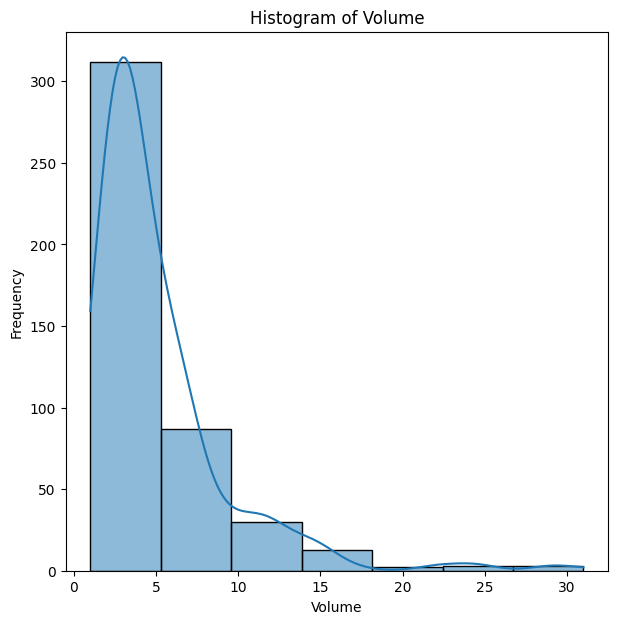

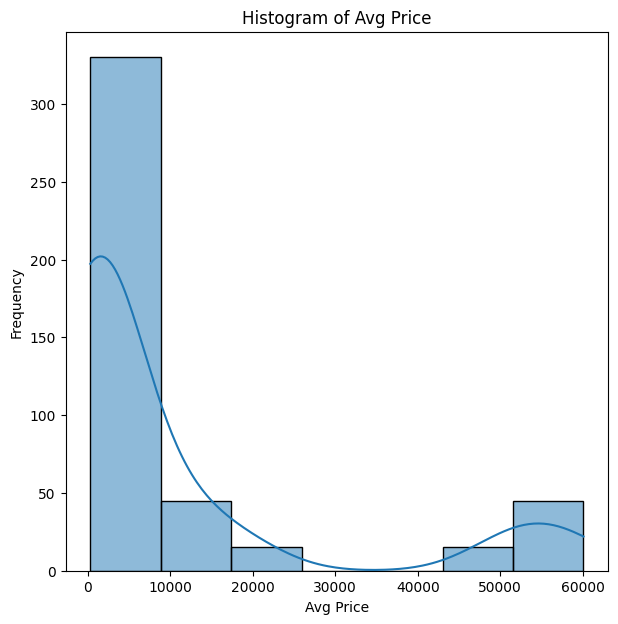

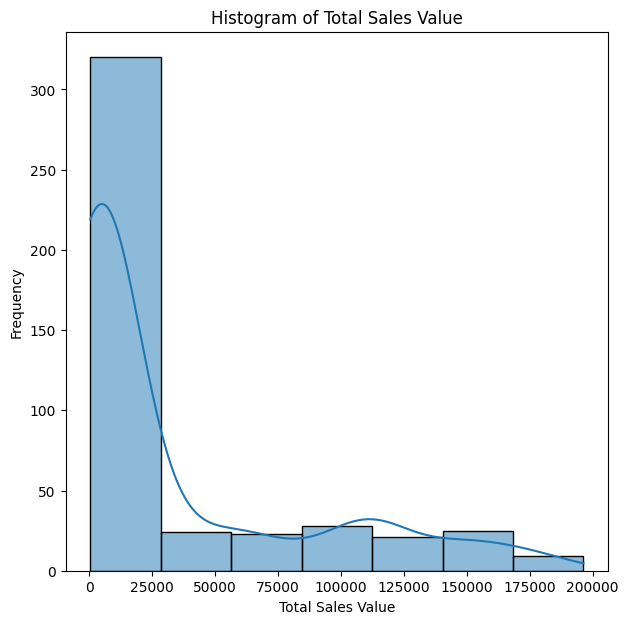

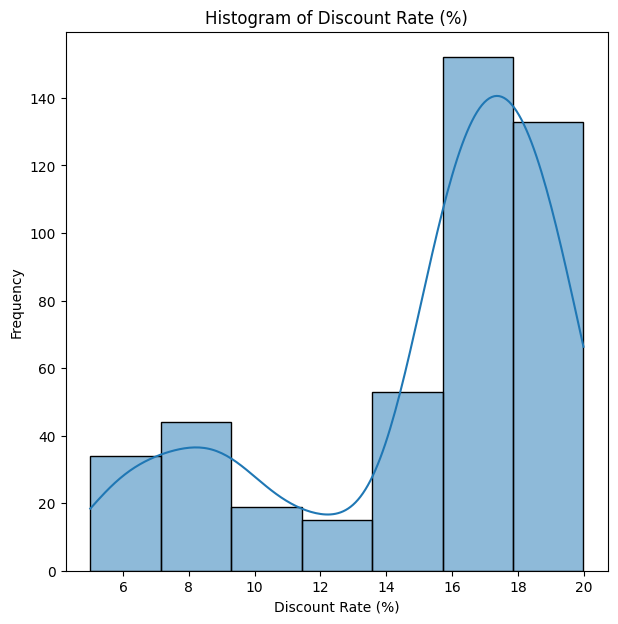

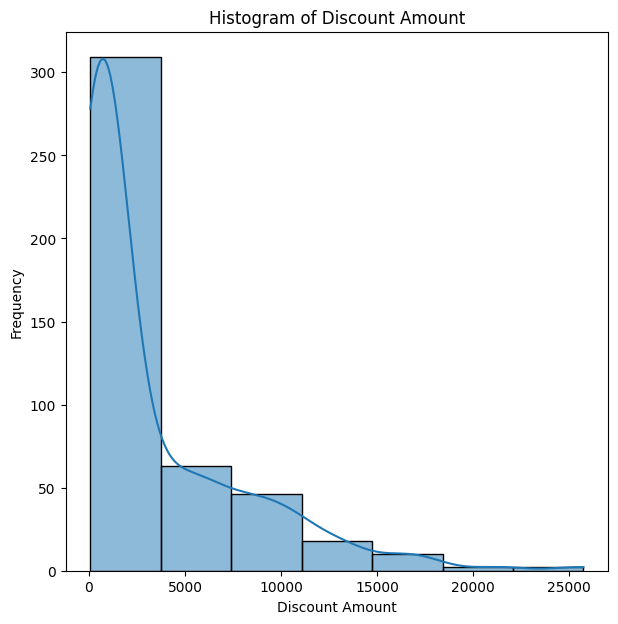

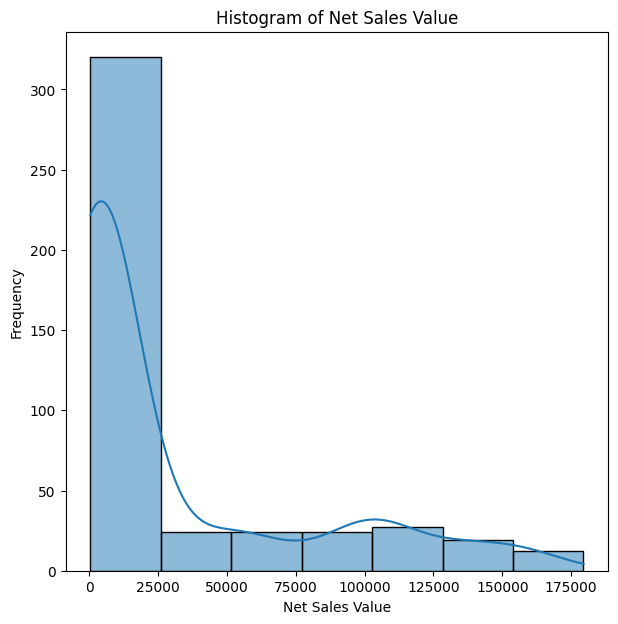

In [10]:
for col in numerical_columns.columns:
  plt.figure(figsize = (7,7))
  sns.histplot(numerical_columns[col], bins = 7, kde = True)
  plt.title(f'Histogram of {col}')
  plt.xlabel(col)
  plt.ylabel('Frequency')
  plt.show()

**Analyze the distribution (e.g., skewness, presence of outliers) and provide inferences.**

The histograms show that most numerical variables are right-skewed, where a large number of values are concentrated at the lower range and fewer values appear at the higher range. Volume, Total Sales Value, Net Sales Value, and Discount Amount have long right tails, indicating the presence of outliers and extreme high values. This suggests that while most transactions are small, a few very large transactions exist. The Discount Rate(%) shows a more balanced distribution with less skewness, meaning discounts are applied more consistently. Overall, the histograms highlight uneven distributions and the presence of extreme values in several numerical columns

**● BOX PLOTS:**

**Create boxplots for numerical variables to identify outliers and the interquartile range.**

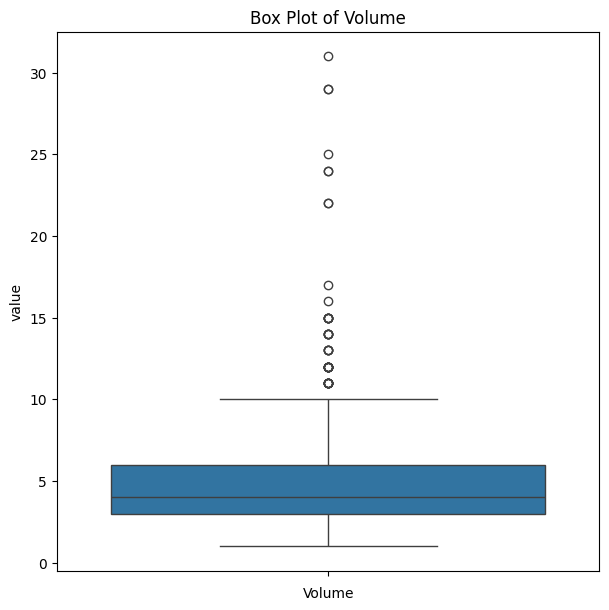

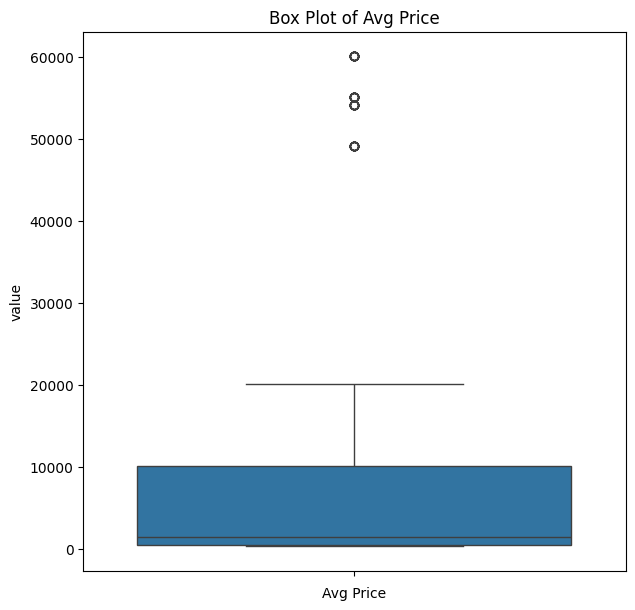

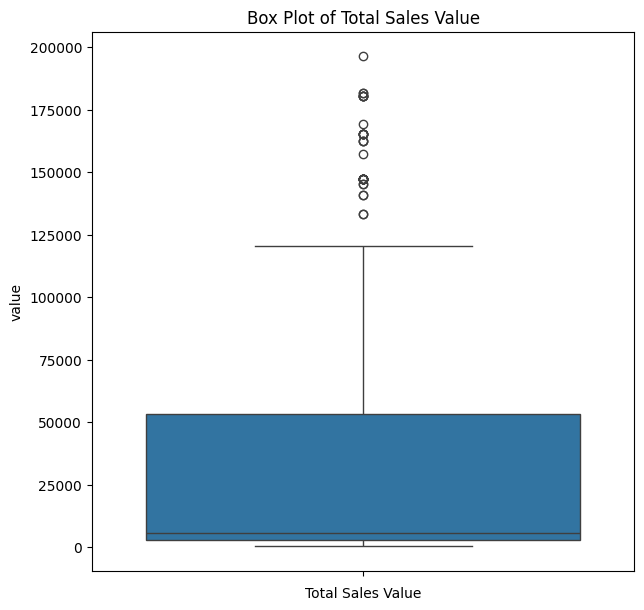

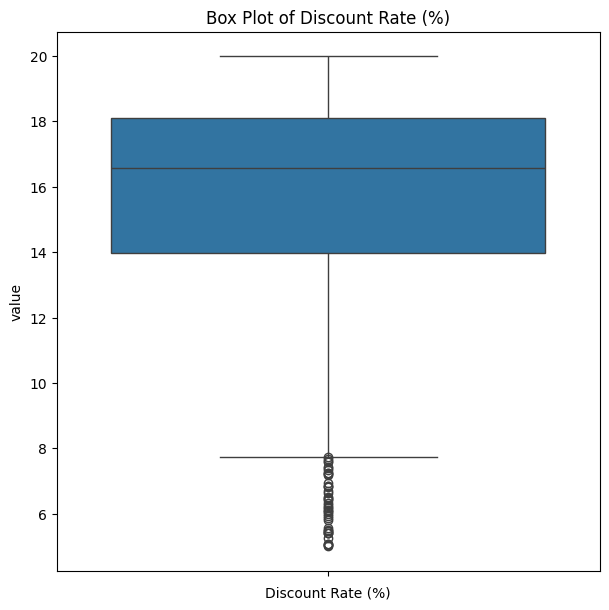

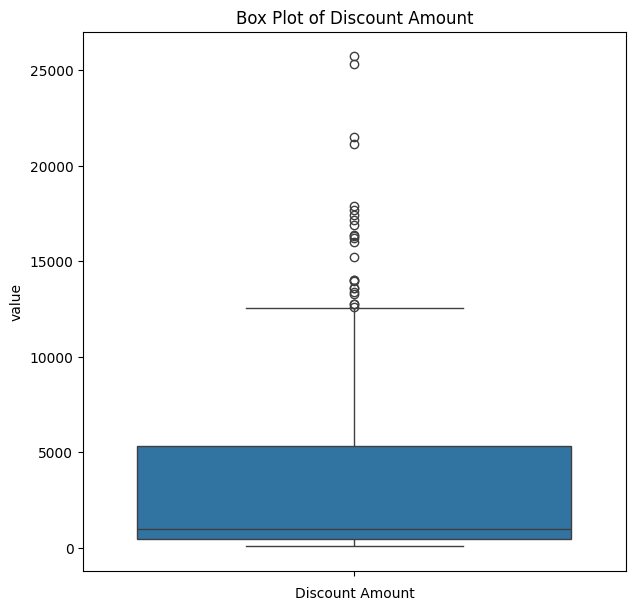

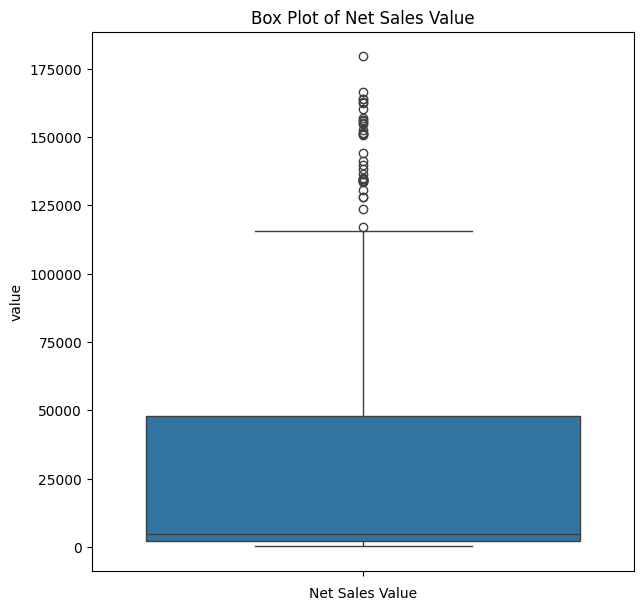

In [11]:
for col in numerical_columns.columns:
  plt.figure(figsize = (7,7))
  sns.boxplot(numerical_columns[col])
  plt.title(f'Box Plot of {col}')
  plt.xlabel(col)
  plt.ylabel('value')
  plt.show()

**Discuss any findings, such as extreme values or unusual distributions.**

The box plot shows the interquartile range (IQR) as the box between Q1 and Q3. Points lying outside are considered outliers in most of the numerical columns. Volume, Total Sales Value, Net Sales Value, and Discount Amount contain several extreme high values, indicating unusually large transactions. These variables are right-skewed, meaning most values are low while a few are very high. The Discount Rate (%) has fewer extreme values, showing more stable and consistent discounts. Overall, the box plots clearly highlight outliers and unusual distributions in the dataset.

**● BAR CHART ANALYSIS FOR CATEGORICAL COLUMN:**




**Identify categorical columns in the Dataset**

In [12]:
categorical_columns = df.select_dtypes(include = ['object'])
categorical_columns

,Date,Day,SKU,City,BU,Brand,Model
0,01-04-2021,Thursday,M01,C,Mobiles,RealU,RU-10
1,01-04-2021,Thursday,M02,C,Mobiles,RealU,RU-9 Plus
2,01-04-2021,Thursday,M03,C,Mobiles,YouM,YM-99
3,01-04-2021,Thursday,M04,C,Mobiles,YouM,YM-99 Plus
4,01-04-2021,Thursday,M05,C,Mobiles,YouM,YM-98
...,...,...,...,...,...,...,...
445,15-04-2021,Thursday,L06,C,Lifestyle,Jeera,M-Casuals
446,15-04-2021,Thursday,L07,C,Lifestyle,Viva,W-Western
447,15-04-2021,Thursday,L08,C,Lifestyle,Viva,W-Lounge
448,15-04-2021,Thursday,L09,C,Lifestyle,Jeera,M-Formals


**Create bar charts to visualize the frequency or count of each category.**

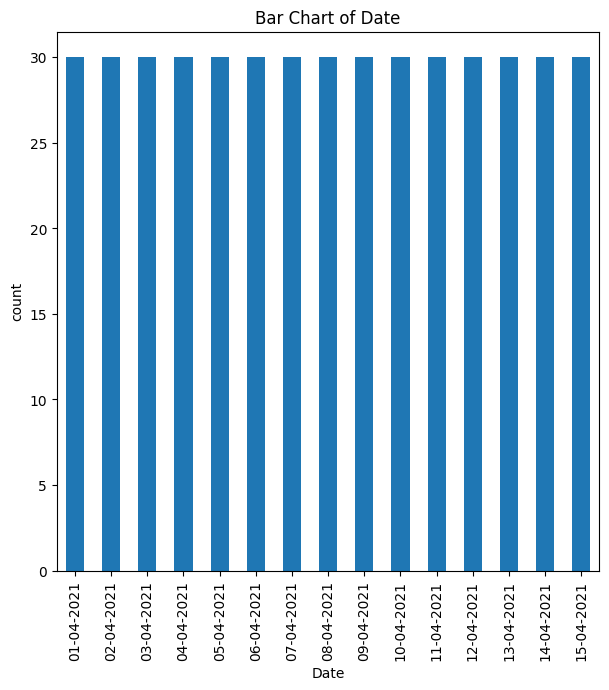

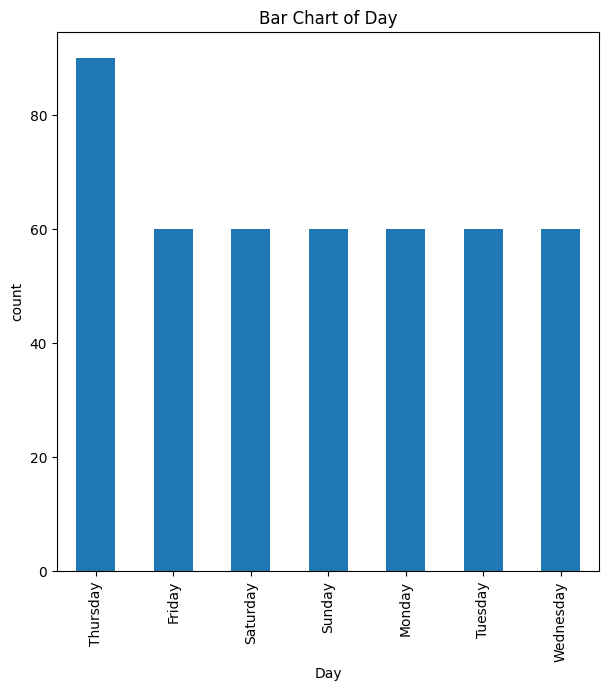

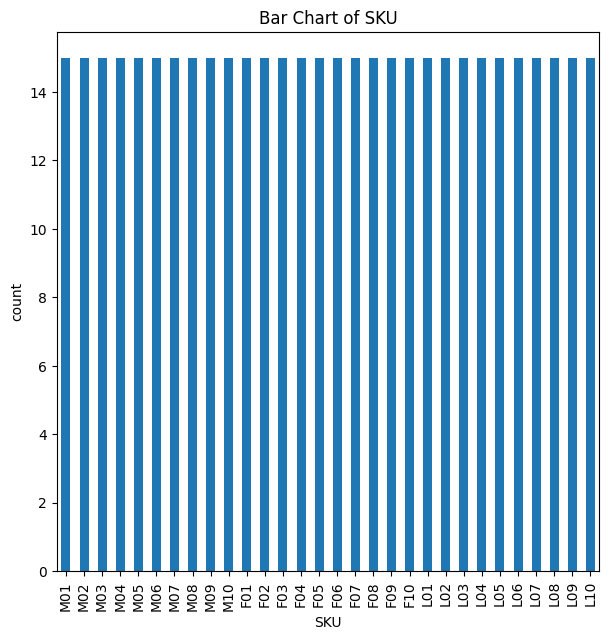

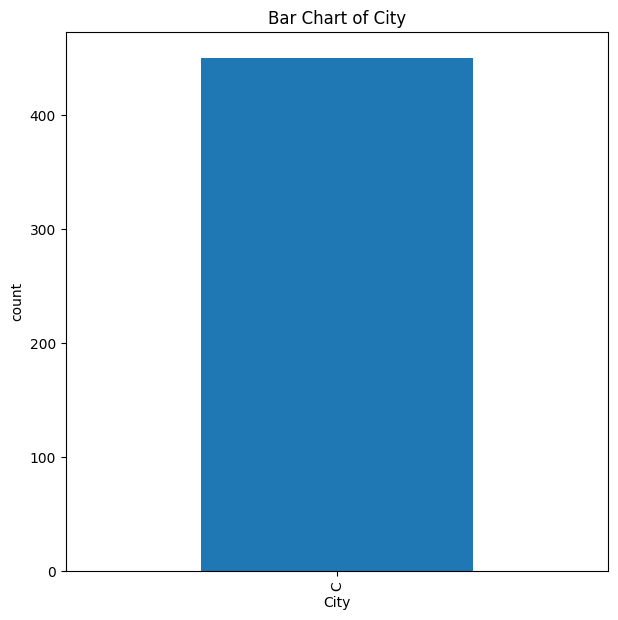

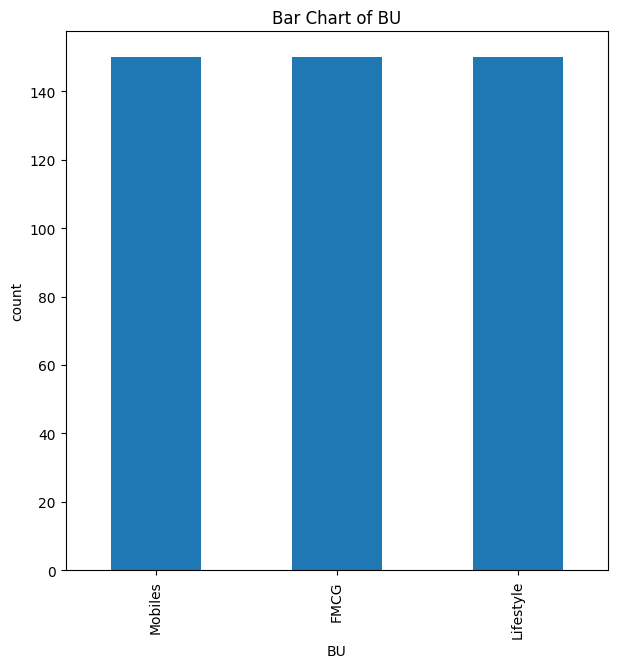

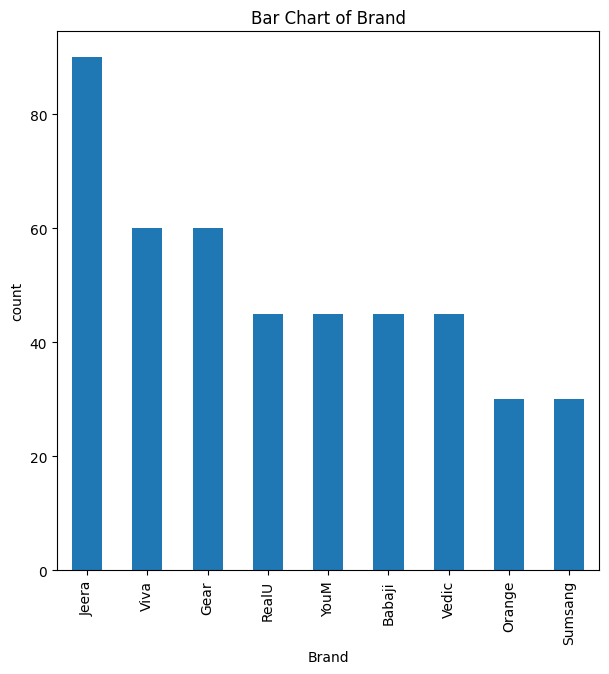

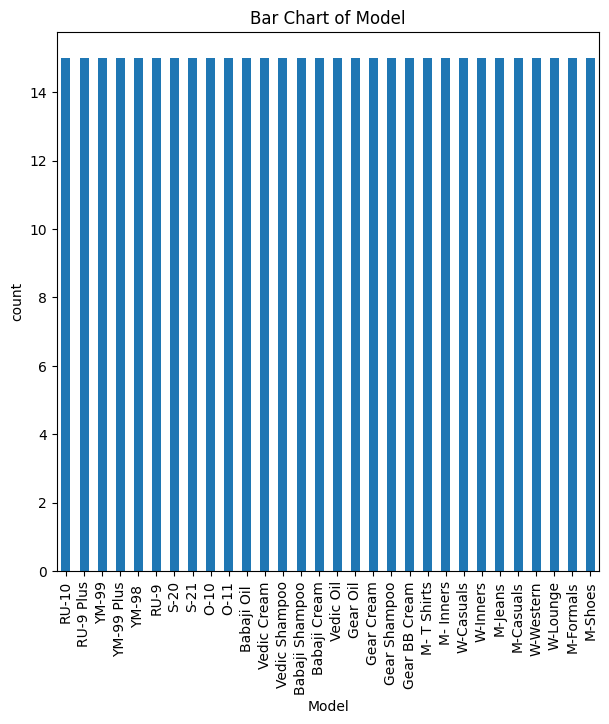

In [13]:
for col in categorical_columns.columns:
  plt.figure(figsize = (7,7))
  df[col].value_counts().plot(kind = 'bar')
  plt.title(f'Bar Chart of {col}')
  plt.xlabel(col)
  plt.ylabel('count')
  plt.show()

**Analyze the distribution of categories and provide insights.**



A bar chart is used to visualize categorical data and compare the frequency of different categories.

Analysis:

The distribution of categorical data was analyzed using bar charts. It was observed that some categories appear more frequently than others, indicating an uneven distribution across categories.

Insights:

Categories with higher frequency contribute more to the dataset and indicate better performance, while categories with lower frequency represent lesser activity and may need improvement or further attention.

# **`Conclusion`**

**●	Summarize the key findings from the descriptive analytics and data visualizations.**

The descriptive analysis helped in understanding the basic characteristics of the dataset. The numerical variables showed skewed distributions with the presence of outliers and extreme values, especially in sales-related columns. And, the visualizations provided clear insights into the data distribution and supported better interpretation of patterns and trends.